# Single-cell ATAC-seq part 3: dimensionality reduction and clustering with SnapATAC2

**Case study: Can liver cell types and hepatocyte zonation be recovered from chromatin accessibility alone?**

Bravo González-Blas C, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024). https://doi.org/10.1038/s41556-023-01316-4

**Research questions:**

1. Can the cell types of the liver be recovered from accessibility alone, without RNA?
2. Is hepatocyte zonation (periportal versus pericentral) visible in the chromatin?
3. Which regions differ between pericentral and periportal hepatocytes, and are they near known zonated genes?

This notebook looks at questions 1 and 2 again, with a second tool, and compares the two tools.

## Introduction

In [part 2](part_2_pycistopic.ipynb), pycisTopic reduced the sparse cell × peak matrix to topics. [SnapATAC2](https://kzhang.org/SnapATAC2/) (Zhang et al., *Nature Methods* 2024) takes another route: **spectral embedding**.

1. It measures how similar every pair of cells is, from the peaks they share (cosine similarity on the binarised matrix, with rare peaks weighted more).
2. It treats the cells as a graph with these similarities as edge weights, and computes the leading eigenvectors of the graph's normalised Laplacian. Cells that are strongly connected end up close together in this "spectral" space.
3. It uses a matrix-free algorithm, so the full cell × cell similarity matrix is never stored, which makes the method fast and scalable to millions of cells.

The spectral components play the same role as the topics: a compact representation for batch correction, clustering and UMAP. We analyse the same cells and peaks as in part 2 and compare the results.

## Step 0: Setup

This notebook uses the `atac-sc` environment and the "Python (atac-sc)" kernel; see [part 1](part_1_qc_preprocessing.ipynb) for how to install them. Input data are in the folder `data` next to this notebook, our results go to `data/results/part_3`.

In [1]:
%matplotlib inline
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import snapatac2 as snap
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 80

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after os.chdir below.
HERE = globals().get("HERE", os.getcwd())

# Input data, in the folder data next to this notebook; your own results in data/results
SC = f"{HERE}/data"
OUT = f"{SC}/results/part_3"
os.makedirs(OUT, exist_ok=True)
os.chdir(OUT)

def results_of(part, filename):
    """Path to a result of an earlier part: yours if it exists, otherwise the pre-generated one."""
    mine = f"{SC}/results/{part}/{filename}"
    return mine if os.path.exists(mine) else f"{SC}/data_generated/{filename}"

adata = sc.read_h5ad(results_of("part_1", "liver_peaks.h5ad"))
adata

AnnData object with n_obs × n_vars = 11297 × 203415
    obs: 'sample', 'cell_type', 'zone', 'n_fragment', 'tsse', 'peak_group'

This is the cell × peak matrix of [part 1](part_1_qc_preprocessing.ipynb), as a regular (in-memory) AnnData object, so both SnapATAC2 and scanpy functions work on it.

## Step 1: Feature selection

Not all peaks are informative. SnapATAC2 removes the most and least accessible peaks (outliers and noise) and keeps the most accessible of the rest.

In [2]:
# marks the selected peaks in adata.var["selected"]; the next steps use only those
snap.pp.select_features(adata, n_features=100000)
print(adata.var["selected"].sum(), "peaks selected")

100000 peaks selected


2026-10-28 02:28:24 - INFO - Selected 100000 features.


## Step 2: Spectral embedding

`snap.tl.spectral` computes 30 spectral components and stores them in `adata.obsm["X_spectral"]`. The first components capture the strongest structure (the main cell types); later ones capture finer differences.

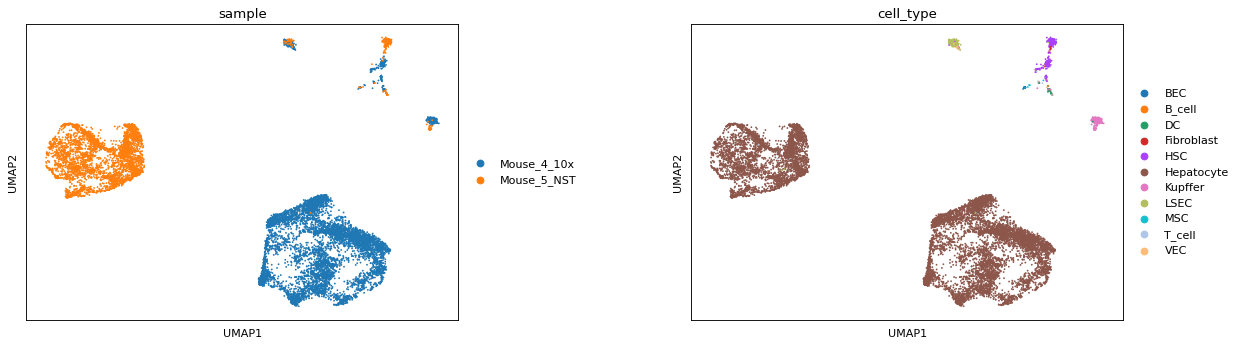

In [3]:
# spectral embedding on the selected peaks; then a UMAP of the 30 components
snap.tl.spectral(adata, n_comps=30)
snap.tl.umap(adata, use_rep="X_spectral")
# wspace: space between the two panels; show=False + plt.show() displays the figure in the notebook
sc.pl.umap(adata, color=["sample", "cell_type"], wspace=0.4, show=False)
plt.show()

## Step 3: Batch correction

The hepatocytes of the two mice form two separate groups: a strong batch effect from the different nuclei isolation protocols. The other cell types are less affected. SnapATAC2 runs Harmony on the spectral components:

2026-10-28 02:29:25,517 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 02:29:25 - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 02:29:27,346 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 02:29:27 - INFO - sklearn.KMeans initialization complete.
2026-10-28 02:29:27,376 - harmonypy - INFO - Iteration 1 of 20
2026-10-28 02:29:27 - INFO - Iteration 1 of 20
2026-10-28 02:29:28,591 - harmonypy - INFO - Iteration 2 of 20
2026-10-28 02:29:28 - INFO - Iteration 2 of 20
2026-10-28 02:29:29,431 - harmonypy - INFO - Iteration 3 of 20
2026-10-28 02:29:29 - INFO - Iteration 3 of 20
2026-10-28 02:29:29,777 - harmonypy - INFO - Iteration 4 of 20
2026-10-28 02:29:29 - INFO - Iteration 4 of 20
2026-10-28 02:29:30,121 - harmonypy - INFO - Iteration 5 of 20
2026-10-28 02:29:30 - INFO - Iteration 5 of 20
2026-10-28 02:29:30,536 - harmonypy - INFO - Iteration 6 of 20
2026-10-28 02:29:30 - INFO - Iteration 6 of 20
2026-10-28

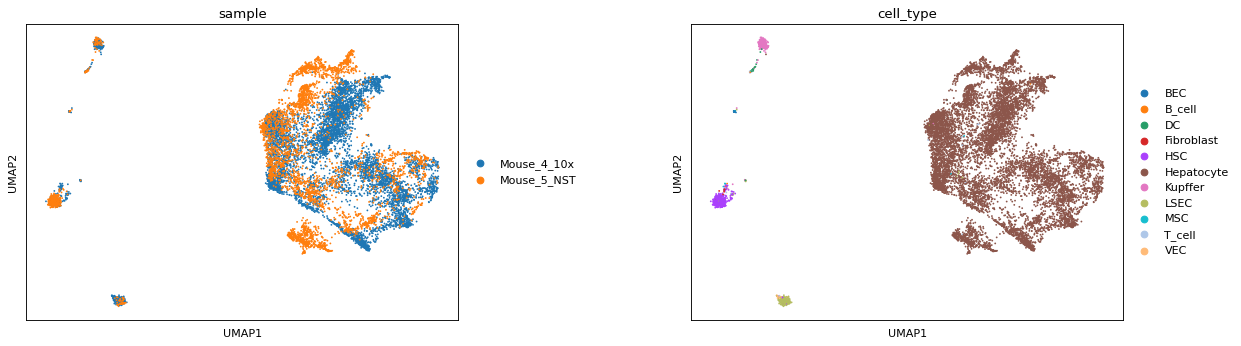

In [4]:
# batch = the column with the sample of each cell; the corrected components go to obsm["X_spectral_harmony"]
snap.pp.harmony(adata, batch="sample", use_rep="X_spectral", max_iter_harmony=20)
snap.tl.umap(adata, use_rep="X_spectral_harmony")
sc.pl.umap(adata, color=["sample", "cell_type"], wspace=0.4, show=False)
plt.show()

## Step 4: Clustering

A k-nearest-neighbour graph on the corrected components, then Leiden clustering:

ARI with cell types: 0.08


... storing 'snap_leiden' as categorical


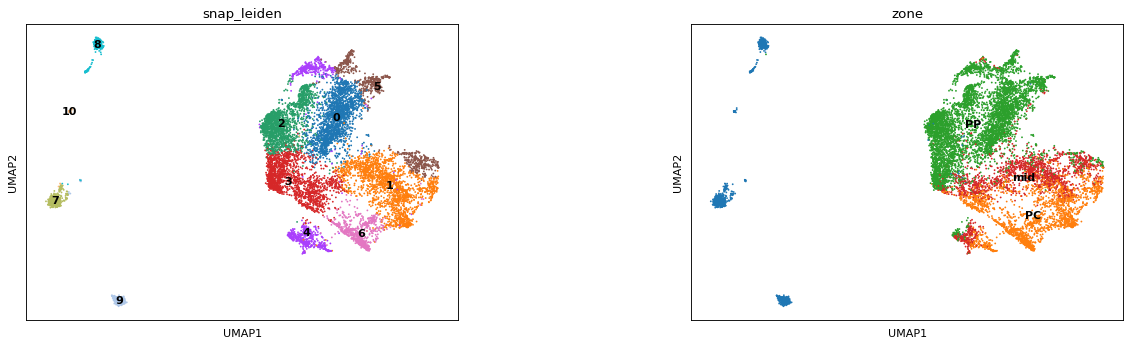

snap_leiden,0,1,2,3,4,5,6,7,8,9,10
cell_type,,,,,,,,,,,
BEC,0,0,0,0,0,0,0,0,0,0,44
B_cell,0,0,0,0,0,1,0,2,7,1,0
DC,1,0,0,0,0,0,0,2,31,1,0
Fibroblast,0,0,0,0,0,0,0,14,0,0,0
HSC,1,0,0,0,0,0,0,515,1,9,0
Hepatocyte,2048,1929,1763,1730,841,806,770,0,1,0,1
Kupffer,0,0,1,0,0,0,0,1,346,2,1
LSEC,0,0,2,3,1,0,0,4,0,345,1
MSC,0,0,0,1,1,0,0,0,0,0,6


In [5]:
# k-nearest-neighbour graph on the corrected components, then Leiden clusters (higher resolution = more clusters)
snap.pp.knn(adata, use_rep="X_spectral_harmony")
snap.tl.leiden(adata, resolution=0.5, key_added="snap_leiden")
sc.pl.umap(adata, color=["snap_leiden", "zone"], wspace=0.4, legend_loc="on data", show=False)
plt.show()
print("ARI with cell types:", round(adjusted_rand_score(adata.obs["cell_type"], adata.obs["snap_leiden"]), 2))
pd.crosstab(adata.obs["cell_type"], adata.obs["snap_leiden"])

Every major non-hepatocyte cell type gets its own cluster (HSC, LSEC, Kupffer, BEC); the rare types join a related cluster (immune cells with Kupffer cells, fibroblasts with HSC, VEC with LSEC, MSC with BEC). Yet the ARI is low (0.08). Why? The hepatocytes, almost 90% of the cells, are split over seven clusters, and the ARI counts every pair of hepatocytes placed in different clusters as a disagreement. The split is not random: compare the cluster and zone UMAPs. Some hepatocyte clusters are mostly periportal, others mostly pericentral, and one or two still reflect the sample (`pd.crosstab(adata.obs["sample"], adata.obs["snap_leiden"])`): Harmony reduced the batch effect but did not remove it completely. A single number like the ARI hides all of this; always look at the contingency table.

### Comparison with pycisTopic

How do the SnapATAC2 clusters compare with the pycisTopic clusters of [part 2](part_2_pycistopic.ipynb) (`cistopic_obj.pkl`, column `pycisTopic_leiden_10_0.6` of `cell_data`)? Let's compute the adjusted Rand index between the two clusterings, and between each clustering and the RNA cell types:

In [6]:
with open(results_of("part_2", "cistopic_obj.pkl"), "rb") as f:
    cistopic_obj = pickle.load(f)
pycistopic_clusters = cistopic_obj.cell_data["pycisTopic_leiden_10_0.6"]

# pycisTopic names cells barcode___sample: build the same names for our cells, then match them (reindex)
names = adata.obs_names + "___" + adata.obs["sample"].astype(str)
both = pd.DataFrame({
    "cell_type": adata.obs["cell_type"].values,
    "snapatac2": adata.obs["snap_leiden"].values,
    "pycistopic": pycistopic_clusters.reindex(names).values,
}).dropna()  # keep only cells present in both analyses
print(f"{len(both)} cells in both analyses")
print("ARI SnapATAC2 vs cell types:", round(adjusted_rand_score(both["cell_type"], both["snapatac2"]), 2))
print("ARI pycisTopic vs cell types:", round(adjusted_rand_score(both["cell_type"], both["pycistopic"]), 2))
print("ARI SnapATAC2 vs pycisTopic:", round(adjusted_rand_score(both["snapatac2"], both["pycistopic"]), 2))

11297 cells in both analyses
ARI SnapATAC2 vs cell types: 0.08
ARI pycisTopic vs cell types: 0.14
ARI SnapATAC2 vs pycisTopic: 0.28


Both tools recover the main cell types: every major non-hepatocyte type has its own cluster in both. The ARIs are low (about 0.08 for SnapATAC2 and 0.14 for pycisTopic against the cell types, 0.28 between the tools) because of how the hepatocytes are split: pycisTopic uses 4 hepatocyte clusters, SnapATAC2 7. The ARI between clusterings is never 1: the numbers of clusters differ (resolution parameters are arbitrary), and hepatocytes, which form a continuum along the zonation axis, are cut into clusters at different places. Clusters are a convenient discretisation, not the truth.

## Step 5: Saving the results

We save the matrix with the SnapATAC2 embedding and clusters for part 4.

In [7]:
adata.write("liver_peaks_snapatac2.h5ad", compression="gzip")
print(f"liver_peaks_snapatac2.h5ad: {os.path.getsize('liver_peaks_snapatac2.h5ad') / 1e6:.0f} MB")

liver_peaks_snapatac2.h5ad: 142 MB


## Summary

| | pycisTopic (part 2) | SnapATAC2 (part 3) |
|---|---|---|
| reduction | topics (LDA) | spectral embedding |
| interpretable components | yes: each topic is a region set | no: components are abstract axes |
| speed | slow (topic models take hours) | fast (minutes) |
| batch correction | Harmony on topics | Harmony on spectral components |
| clusters vs RNA cell types (ARI) | 0.14 | 0.08 |

Both give a sensible representation of the cells. Topics have the advantage that they are directly interpretable as sets of co-accessible regions; SnapATAC2 is much faster and scales to very large datasets. In [part 4](part_4_dars.ipynb) we use both to find differentially accessible regions.

## Exercises

1. Compute fewer or more spectral components (`snap.tl.spectral(adata, n_comps=10)` or `n_comps=50`), then repeat the batch correction, clustering and ARI. Do the hepatocyte zones still separate with 10 components?
2. Skip the feature selection and use all peaks (`snap.pp.select_features(adata, n_features=adata.n_vars)`). Does the UMAP change?
3. Single-cell ATAC data differ a lot in the number of fragments per cell. Plot the first two spectral components (`adata.obsm["X_spectral"][:, 0]` and `[:, 1]`) against `np.log10(adata.obs["n_fragment"])`. Does one of the components mainly reflect sequencing depth rather than biology?